# Example 2.2 — Similarity search: close analogues of imatinib

A reproducible record of an AI-assisted BindingDB analysis: each prompt, the BindingDB tool calls that answered it with their recorded results, the answer, and its figures. Run all cells to show the recorded results, or rerun every call on your own copy of the database and check each result against the recorded one.

- **Date:** 2026-11-23
- **Model:** claude-opus-5-5
- **Data:** BindingDB release **202611** (`BDB-mySQL_All_202611_dmp.zip`, SHA-256 `daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381`)
- **Database build:** 2026-11-21T01:08:15+00:00, DuckDB 1.5.6
- **Derived data:** standard InChIKeys computed from SMILES by RDKit 2026.03.6; compound_property computed from SMILES (largest fragment) by RDKit 2026.03.6
- **Server:** mcp-bindingdb v0.1.17, commit [`79dae5d22c0f`](https://github.com/sbl-sdsc/mcp-bindingdb/commit/79dae5d22c0f15b8ded9b49adc8b105f0463703a)
- **Software:** python 3.12.7, duckdb 1.5.6, rdkit 2026.03.6, mcp 2.3.0, gemmi 0.7.5
- **Notebook generated:** 2026-11-24T04:55:16Z
- **Contents:** 1 exchange · 7 tool calls · 1 figure · 1 code cell

### How to run

Keep the notebook in its folder, which holds everything it needs: `requirements.txt` (mcp-bindingdb at its commit and the versions of the packages it needs), the recorded results in `data/` and the figures in `figures/`. With [uv](https://docs.astral.sh/uv/), from that folder (replace the path with yours):

```bash
cd /path/to/2.2-similarity-search-notebook
uv run --no-project --with-requirements requirements.txt --with jupyterlab jupyter lab 2.2-similarity-search-notebook.ipynb
```

then choose Run → Run All Cells. The first start installs the packages, which takes a minute or two; the cells show the recorded results, so no database is needed. Without uv: `pip install -r requirements.txt jupyterlab`, then `jupyter lab 2.2-similarity-search-notebook.ipynb` in the folder.

### How to rerun the calls

To rerun every BindingDB call on your own copy of release 202611 and check each result against the recorded one, set `RERUN = True` in the setup cell and run all cells, or rerun the notebook without opening Jupyter, writing a copy with the new results:

```bash
cd /path/to/2.2-similarity-search-notebook
BINDINGDB_RERUN=1 uv run --no-project --with-requirements requirements.txt --with nbconvert jupyter nbconvert --to notebook --execute --output 2.2-similarity-search-notebook-rerun.ipynb 2.2-similarity-search-notebook.ipynb
```

A rerun needs the database: the one `BINDINGDB_DUCKDB=/path/to/bindingdb_202611.duckdb` names (put it before `uv run`), else the newest one mcp-bindingdb built on this computer, for example for Claude Desktop. With neither, the first rerun builds one, which takes about half an hour and 2.4 GB. To build exactly release 202611, with a clone of mcp-bindingdb:

```bash
git clone https://github.com/sbl-sdsc/mcp-bindingdb.git
cd mcp-bindingdb
git checkout 79dae5d22c0f15b8ded9b49adc8b105f0463703a
scripts/build_duckdb.sh --release 202611
```

The setup cell checks the database's release and source checksum against the recorded ones.

Run as it is, each call cell shows its recorded result, read from `data/` and checked against the SHA-256 digest recorded in the cell. Rerun, it shows the new result with ✅ when it matches the recorded one (floats to 10 significant digits, ids of viewers and files left out). Calls to PubChem, RCSB or PDBe depend on those services and may differ. The prose answers are the model's and are not recomputed. Code cells hold the analysis code the model wrote; they run as written (reading the results with `replay.result(n)`, the result of Call n) and draw their figures again, which are not compared.

In [ ]:
# Shows the results recorded during the session (data/), so the notebook runs without a database. Set
# RERUN = True (or start Jupyter with BINDINGDB_RERUN=1) to rerun every BindingDB call on a local copy of
# the database instead and check it against its recorded result: see 'How to rerun the calls' above.
from mcp_bindingdb.notebook import Replay

RERUN = False
replay = Replay(release='202611', source_zip_sha256='daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381', rerun=RERUN)

Recorded with BindingDB release 202611, mcp-bindingdb v0.1.17 (commit 79dae5d22c0f)
python 3.12.7, duckdb 1.5.6, rdkit 2026.03.6, mcp 2.3.0, gemmi 0.7.5


## Exchange 1

**👤 User**

Find close analogues of imatinib (Tanimoto ≥ 0.7) that bind any target below 100 nM.

In [ ]:
# Call 1 · chemical_name_to_smiles · ran 2026-11-24 04:55:03 UTC
await replay.call(1, 'chemical_name_to_smiles', {'name': 'imatinib'},
                  sha256='ab798268598a210bd1b28860c3d648554792661ff34dba55d116c5a7fc8e6796')

**Call 1** · `chemical_name_to_smiles` · recorded result · sha256 `ab798268598a…` · uses PubChem, whose answers can change

| name | smiles |
| --- | --- |
| imatinib | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)CC1 |

```json
{
  "query": "imatinib",
  "resolved": true,
  "source": "bindingdb",
  "smiles": "CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)CC1",
  "inchi_key": "KTUFNOKKBVMGRW-UHFFFAOYSA-N",
  "monomerid": 13530,
  "ambiguous": false
}
```

**candidates**: 2 rows

| monomerid | bdbm_id | name | inchi_key | smiles | n_activities |
| --- | --- | --- | --- | --- | --- |
| 13530 | BDBM13530 | Gleevec | KTUFNOKKBVMGRW-UHFFFAOYSA-N | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)CC1 | 1156 |
| 31341 | BDBM31341 | IMATINIB | KTUFNOKKBVMGRW-UHFFFAOYSA-N | Cc1ccc(cc1Nc2nccc(n2)c3cccnc3)NC(=O)c4ccc(cc4)CN5CCN(CC5)C | 0 |

**sources_tried**: 1 row

| source | status |
| --- | --- |
| bindingdb | found |


In [ ]:
# Call 2 · similarity_search · ran 2026-11-24 04:55:11 UTC
arguments = {
    'smiles': 'CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)CC1',
    'threshold': 0.7,
    'limit': 500,
}
await replay.call(2, 'similarity_search', arguments,
                  sha256='8b7c1214cf827d27c8739787764a9393cce9bc5e321bcbf63443509c7f9fc8c7')

**Call 2** · `similarity_search` · recorded result · sha256 `8b7c1214cf82…`

| name | smiles |
| --- | --- |
| query | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cccnc2)n1 |

```json
{
  "query": {
    "input": "CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)CC1",
    "canonical": "Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cccnc2)n1",
    "threshold": 0.7,
    "fingerprint": "Morgan radius 2, 2048 bits, largest fragment"
  },
  "n_similar_compounds": 83,
  "compounds_searched": 1466457,
  "search_set_size": 1466457
}
```

_83 rows_

| monomerid | bdbm_id | name | smiles | mol_weight | n_activities | n_targets | similarity |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 13530 | BDBM13530 | Gleevec | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)CC1 | 493.26 | 1156 | 459 | 1 |
| 86734 | BDBM86734 | Gleevec | Cc3ccc(NC(=O)c2ccc(CN1CCN(C)CC1)cc2)cc3Nc5nccc(c4cccnc4)n5 | 493.26 | 66 | 10 | 1 |
| 31341 | BDBM31341 | IMATINIB | Cc1ccc(cc1Nc2nccc(n2)c3cccnc3)NC(=O)c4ccc(cc4)CN5CCN(CC5)C |  | 0 | 0 | 1 |
| 612739 | BDBM612739 | US11725005, Compound 101 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3cccnc3)c2)CC1 | 570.29 | 3 | 3 | 0.929 |
| 50434581 | BDBM50434581 | imatinib-CD3 | \[2H\]C(\[2H\])(\[2H\])N5CCN(Cc4ccc(C(=O)Nc3ccc(C)c(Nc2nccc(c1cccnc1)n2)c3)cc4)CC5 | 496.58 | 2 | 2 | 0.9 |
| 50634633 | BDBM50634633 |  | \[2H\]C(\[2H\])(\[2H\])N5CCN(Cc4ccc(C(=O)Nc3ccc(C)c(Nc2nccc(c1cccnc1)n2)c3)cc4)CC5 | 496.28 | 2 | 1 | 0.9 |
| 50444657 | BDBM50444657 | CHEMBL3098615 | Cc1ccc(NC(=O)c2ccc(CN3CCN(CCO)CC3)cc2)cc1Nc1nccc(n1)-c1cccnc1 | 523.63 | 1 | 1 | 0.886 |
| 50444658 | BDBM50444658 | CHEMBL3098616 | Cc1ccc(NC(=O)c2ccc(CN3CCN(CCF)CC3)cc2)cc1Nc1nccc(n1)-c1cccnc1 | 525.62 | 1 | 1 | 0.873 |
| 50444656 | BDBM50444656 | CHEMBL3098614 | Cc1ccc(NC(=O)c2ccc(CN3CCN(Cc4ccc(I)cc4)CC3)cc2)cc1Nc1nccc(n1)-c1cccnc1 | 695.6 | 1 | 1 | 0.871 |
| 612799 | BDBM612799 | US11725005, Compound 309 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3ccccc3)c2)CC1 | 569.29 | 3 | 3 | 0.861 |
| 50434582 | BDBM50434582 | CHEMBL2386594 | Cc1ccc(NC(=O)c2ccc(CN3CCNCC3)cc2)cc1Nc1nccc(n1)-c1cccnc1 | 575.68 | 5 | 2 | 0.845 |
| 50313640 | BDBM50313640 | N-(4-methyl-3-(4-(6-methylpyridin-3-yl)pyrimidin-2-ylamino)phenyl)-4-((4-methylpiperazin-1-yl)methyl)benzamide | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3ccc(C)nc3)c2)CC1 | 507.629 | 2 | 2 | 0.843 |
| 612807 | BDBM612807 | US11725005, Compound 401 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3cccc(C)c3)c2)CC1 | 583.31 | 3 | 3 | 0.827 |
| 612740 | BDBM612740 | US11725005, Compound 102 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3ccccn3)c2)CC1 | 570.29 | 3 | 3 | 0.824 |
| 50432866 | BDBM50432866 | CHEMBL382605 | CN1CCN(Cc2ccc(cc2Cl)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)CC1 | 528.05 | 1 | 1 | 0.824 |
| 481130 | BDBM481130 | US10906896, Cpd 830 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3cc(C)ccn3)c2)CC1 | 584.3 | 6 | 3 | 0.822 |
| 612741 | BDBM612741 | US11725005, Compound 103 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3ccncc3)c2)CC1 | 570.29 | 3 | 3 | 0.822 |
| 50290422 | BDBM50290422 | 4-(4-Methyl-piperazin-1-ylmethyl)-N-\[3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-benzamide | CN1CCN(Cc2ccc(cc2)C(=O)Nc2cccc(Nc3nccc(n3)-c3cccnc3)c2)CC1 | 479.576 | 12 | 11 | 0.812 |
| 481131 | BDBM481131 | US10906896, Cpd 832 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3ccn(C)n3)c2)CC1 | 573.3 | 9 | 3 | 0.811 |
| 612811 | BDBM612811 | US11725005, Compound 402 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3ccc(C)cc3)c2)CC1 | 583.31 | 3 | 3 | 0.811 |
| 481146 | BDBM481146 | US10906896, Cpd 8300 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3ccn(C)n3)c2)CC1 |  | 0 | 0 | 0.811 |
| 481129 | BDBM481129 | US10906896, Cpd 820 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3ccc(C)cn3)c2)CC1 | 584.3 | 6 | 3 | 0.8 |
| 50178611 | BDBM50178611 | 3-bromo-N-(4-methyl-3-(4-(pyridin-3-yl)pyrimidin-2-ylamino)phenyl)-4-((4-methylpiperazin-1-yl)methyl)benzamide | CN1CCN(Cc2ccc(cc2Br)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)CC1 | 571.17 | 3 | 3 | 0.8 |
| 50178617 | BDBM50178617 | 3-fluoro-N-(4-methyl-3-(4-(pyridin-3-yl)pyrimidin-2-ylamino)phenyl)-4-((4-methylpiperazin-1-yl)methyl)benzamide | CN1CCN(Cc2ccc(cc2F)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)CC1 | 511.25 | 3 | 3 | 0.8 |
| 50432865 | BDBM50432865 | CHEMBL203071 | CN1CCN(Cc2ccc(cc2I)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)CC1 | 619.5 | 1 | 1 | 0.8 |
| 612798 | BDBM612798 | US11725005, Compound 305 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)N3CCCC3)c2)CC1 | 562.32 | 3 | 3 | 0.789 |
| 612893 | BDBM612893 | US11725005, Compound 8300 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3cnn(C)c3)c2)CC1 | 573.3 | 3 | 3 | 0.789 |
| 612837 | BDBM612837 | US11725005, Compound 404 | COc1cccc(c1)-c1cncc(c1)-c1ccnc(Nc2cc(NC(=O)c3ccc(CN4CCN(C)CC4)cc3)ccc2C)n1 | 599.3 | 3 | 3 | 0.785 |
| 481104 | BDBM481104 | US10906896, Cpd 101 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cncc(C3=NN=C(C(=O)Nc4cccnc4)C3)c2)n1 | 679.31 | 3 | 3 | 0.78 |
| 481135 | BDBM481135 | BDBM481139 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3ccns3)c2)CC1 | 576.24 | 9 | 3 | 0.779 |
| 481143 | BDBM481143 | US10906896, Cpd 8270 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3nccs3)c2)CC1 | 576.24 | 6 | 3 | 0.779 |
| 481144 | BDBM481144 | US10906896, Cpd 8280 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3ncc(C)s3)c2)CC1 | 590.26 | 6 | 3 | 0.779 |
| 612764 | BDBM612764 | US11725005, Compound 107 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cncc(-c3ccn\[nH\]3)c2)n1 | 559.28 | 3 | 3 | 0.779 |
| 612767 | BDBM612767 | US11725005, Compound 108 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cncc(-c3\[nH\]ncc3C)c2)n1 | 573.3 | 3 | 3 | 0.779 |
| 612784 | BDBM612784 | US11725005, Compound 118 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cncc(-c3cn\[nH\]c3)c2)n1 | 559.28 | 3 | 3 | 0.779 |
| 612785 | BDBM612785 | US11725005, Compound 119 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cncc(-c3cn\[nH\]c3C)c2)n1 | 573.3 | 3 | 3 | 0.779 |
| 612786 | BDBM612786 | US11725005, Compound 201 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3ncco3)c2)CC1 | 560.26 | 3 | 3 | 0.779 |
| 481139 | BDBM481139 | US10906896, Cpd 8230 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3ccns3)c2)CC1 |  | 0 | 0 | 0.779 |
| 612796 | BDBM612796 | US11725005, Compound 303 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-n3cccn3)c2)CC1 | 559.28 | 3 | 3 | 0.772 |
| 481128 | BDBM481128 | US10906896, Cpd 809 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3oncc3C)c2)CC1 | 574.28 | 6 | 3 | 0.769 |
| 481136 | BDBM481136 | US10906896, Cpd 8180 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3sncc3C)c2)CC1 | 590.26 | 6 | 3 | 0.769 |
| 481138 | BDBM481138 | US10906896, Cpd 8200 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3cnsc3)c2)CC1 | 576.24 | 6 | 3 | 0.769 |
| 612772 | BDBM612772 | US11725005, Compound 113 | Cc1cc(-c2cncc(-c3ccnc(Nc4cc(NC(=O)c5ccc(CN6CCN(C)CC6)cc5)ccc4C)n3)c2)\[nH\]n1 | 573.3 | 6 | 3 | 0.769 |
| 612841 | BDBM612841 | US11725005, Compound 405 | COc1ccc(cc1)-c1cncc(c1)-c1ccnc(Nc2cc(NC(=O)c3ccc(CN4CCN(C)CC4)cc3)ccc2C)n1 | 599.3 | 3 | 3 | 0.769 |
| 50178615 | BDBM50178615 | N-(4-methyl-3-(4-(pyridin-3-yl)pyrimidin-2-ylamino)phenyl)-4-((4-methylpiperazin-1-yl)methyl)-3-(trifluoromethyl)benzamide | CN1CCN(Cc2ccc(cc2C(F)(F)F)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)CC1 | 561.25 | 3 | 3 | 0.769 |
| 50341234 | BDBM50341234 | 4-(chloromethyl)-N-(4-methyl-3-(4-(pyridin-3-yl)pyrimidin-2-ylamino)phenyl)benzamide | Cc1ccc(NC(=O)c2ccc(CCl)cc2)cc1Nc1nccc(n1)-c1cccnc1 | 429.14 | 3 | 3 | 0.768 |
| 481134 | BDBM481134 | US10906896, Cpd 8130 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3nnc(C)o3)c2)CC1 | 575.28 | 6 | 3 | 0.759 |
| 481137 | BDBM481137 | US10906896, Cpd 8190 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3cc(C)ns3)c2)CC1 | 590.26 | 6 | 3 | 0.759 |
| 481142 | BDBM481142 | US10906896, Cpd 8260 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3nnc(C)s3)c2)CC1 | 591.25 | 6 | 3 | 0.759 |
| 481145 | BDBM481145 | US10906896, Cpd 8290 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3nc(C)cs3)c2)CC1 | 590.26 | 6 | 3 | 0.759 |
| 612789 | BDBM612789 | US11725005, Compound 202 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3nc(C)co3)c2)CC1 | 574.28 | 3 | 3 | 0.759 |
| 612791 | BDBM612791 | US11725005, Compound 207 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3cc(C)no3)c2)CC1 | 574.28 | 3 | 3 | 0.759 |
| 612865 | BDBM612865 | US11725005, Compound 8230 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3cnns3)c2)CC1 | 577.24 | 3 | 3 | 0.759 |
| 106568 | BDBM106568 | US8586600, II-8 | Cc1ccc(NC(=O)c2ccc(CN3C(=O)C=CC3=O)cc2)cc1Nc1nccc(n1)-c1cccnc1 \|c:16\| | 490.18 | 1 | 1 | 0.753 |
| 481133 | BDBM481133 | US10906896, Cpd 8120 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3nnco3)c2)CC1 | 561.26 | 6 | 3 | 0.75 |
| 481140 | BDBM481140 | US10906896, Cpd 8240 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3snnc3C)c2)CC1 | 591.25 | 6 | 3 | 0.75 |
| 481141 | BDBM481141 | US10906896, Cpd 8250 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3nncs3)c2)CC1 | 577.24 | 6 | 3 | 0.75 |
| 50355495 | BDBM50355495 | CHEMBL1908391 | Cc1ccc(cc1Nc2nc(cs2)c3cccnc3)NC(=O)c4ccc(cc4)CN5CCN(CC5)C | 498.22 | 452 | 378 | 0.747 |
| 50599045 | BDBM50599045 | CHEMBL5207077 | CN1CCN(Cc2ccc(NC(=O)c3ccc(C)c(Nc4nccc(n4)-c4cccnc4)c3)cc2C(F)(F)F)CC1 | 561.61 | 2 | 1 | 0.747 |
| 734447 | BDBM734447 | US20250129067, Compound Masitinib | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nc(-c2cccnc2)cs1 | 498.22 | 1 | 1 | 0.747 |
| 50341235 | BDBM50341235 | 4-(aminomethyl)-N-(4-methyl-3-(4-(pyridin-3-yl)pyrimidin-2-ylamino)phenyl)benzamide | Cc1ccc(NC(=O)c2ccc(CN)cc2)cc1Nc1nccc(n1)-c1cccnc1 | 410.19 | 3 | 3 | 0.743 |
| 481122 | BDBM481122 | US10906896, Cpd 309 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cncc(C3=NN=C(C(=O)Nc4ccccc4)C3)c2)n1 | 678.32 | 3 | 3 | 0.735 |
| 612775 | BDBM612775 | US11725005, Compound 114 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cncc(-c3cc(C(N)=O)n\[nH\]3)c2)n1 | 602.29 | 3 | 3 | 0.732 |
| 612779 | BDBM612779 | US11725005, Compound 116 | CNC(=O)c1cc(-c2cncc(-c3ccnc(Nc4cc(NC(=O)c5ccc(CN6CCN(C)CC6)cc5)ccc4C)n3)c2)\[nH\]n1 | 616.3 | 3 | 3 | 0.732 |
| 50287090 | BDBM50287090 | 4-Chloro-N-\[4-methyl-3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-benzamide | Cc1ccc(NC(=O)c2ccc(Cl)cc2)cc1Nc1nccc(n1)-c1cccnc1 | 415.875 | 14 | 8 | 0.725 |
| 481124 | BDBM481124 | US10906896, Cpd 402 | Cc1ccc(NC(=O)C2=NN=C(c3cncc(-c4ccnc(Nc5cc(NC(=O)c6ccc(CN7CCN(C)CC7)cc6)ccc5C)n4)c3)C2)cc1 | 692.33 | 3 | 3 | 0.723 |
| 612790 | BDBM612790 | US11725005, Compound 203 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3nc(co3)C(N)=O)c2)CC1 | 603.27 | 3 | 3 | 0.723 |
| 50175491 | BDBM50175491 | 4-Methyl-N-\[4-methyl-3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-benzamide | Cc1ccc(cc1)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 | 395.17 | 19 | 8 | 0.721 |
| 106558 | BDBM106558 | US8586600, II-53 | Cc1ccc(NC(=O)c2ccc(NC(=O)CCl)cc2)cc1Nc1nccc(n1)-c1cccnc1 | 472.14 | 3 | 2 | 0.718 |
| 481123 | BDBM481123 | US10906896, Cpd 401 | Cc1cccc(NC(=O)C2=NN=C(c3cncc(-c4ccnc(Nc5cc(NC(=O)c6ccc(CN7CCN(C)CC7)cc6)ccc5C)n4)c3)C2)c1 | 692.33 | 3 | 3 | 0.718 |
| 50341236 | BDBM50341236 | 4-((2-chloroacetamido)methyl)-N-(4-methyl-3-(4-(pyridin-3-yl)pyrimidin-2-ylamino)phenyl)benzamide | Cc1ccc(NC(=O)c2ccc(CNC(=O)CCl)cc2)cc1Nc1nccc(n1)-c1cccnc1 | 486.16 | 3 | 3 | 0.716 |
| 481106 | BDBM481106 | US10906896, Cpd 103 | Cc1cc(NC(=O)C2=NN=C(c3cncc(-c4ccnc(Nc5cc(NC(=O)c6ccc(CN7CCN(C)CC7)cc6)ccc5C)n4)c3)C2)ccn1 | 693.33 | 3 | 3 | 0.714 |
| 612783 | BDBM612783 | US11725005, Compound 117 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cncc(-c3cc(C(=O)N(C)C)n\[nH\]3)c2)n1 | 630.32 | 3 | 3 | 0.714 |
| 50215564 | BDBM50215564 | 4-(((2-chloroethyl)(methyl)amino)methyl)-N-(4-methyl-3-(4-(pyridin-3-yl)pyrimidin-2-ylamino)phenyl)benzamide | CN(CCCl)Cc1ccc(cc1)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 | 486.19 | 1 | 1 | 0.711 |
| 50215560 | BDBM50215560 | 4-((bis(2-chloroethyl)amino)methyl)-N-(4-methyl-3-(4-(pyridin-3-yl)pyrimidin-2-ylamino)phenyl)benzamide | Cc1ccc(NC(=O)c2ccc(CN(CCCl)CCCl)cc2)cc1Nc1nccc(n1)-c1cccnc1 | 534.17 | 1 | 1 | 0.707 |
| 50612382 | BDBM50612382 | CHEMBL5269948 | CN1CCN(CCCCC(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)CC1 | 459.6 | 1 | 1 | 0.707 |
| 50240407 | BDBM50240407 | N-(4-methyl-3-(4-(pyridin-3-yl)pyrimidin-2-ylamino)phenyl)benzamide | Cc1ccc(NC(=O)c2ccccc2)cc1Nc1nccc(n1)-c1cccnc1 | 381.16 | 17 | 9 | 0.706 |
| 481121 | BDBM481121 | US10906896, Cpd 305 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cncc(C3=NN=C(C(=O)N4CCCC4)C3)c2)n1 | 656.33 | 3 | 3 | 0.706 |
| 50155561 | BDBM50155561 | 4-Methyl-piperazine-1-carboxylic acid \[4-methyl-3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-amide | CN1CCN(CC1)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 | 403.21 | 2 | 2 | 0.704 |
| 481105 | BDBM481105 | US10906896, Cpd 102 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cncc(C3=NN=C(C(=O)Nc4ccccn4)C3)c2)n1 | 679.31 | 3 | 3 | 0.701 |
| 50612381 | BDBM50612381 | CHEMBL5279557 | CN1CCN(CC23CC(C2)(C3)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)CC1 | 483.62 | 1 | 1 | 0.701 |
| 481132 | BDBM481132 | US10906896, Cpd 880 | Cc1ccc(NC(=O)c2ccc(CN3CCNCC3)cc2)cc1Nc1nccc(n1)-c1cncc(c1)-c1ccccn1 | 556.27 | 6 | 3 | 0.7 |
| 50132709 | BDBM50132709 | 4-amino-N-(4-methyl-3-(4-(pyridin-3-yl)pyrimidin-2-ylamino)phenyl)benzamide | Cc1ccc(NC(=O)c2ccc(N)cc2)cc1Nc1nccc(n1)-c1cccnc1 | 396.17 | 3 | 3 | 0.7 |


In [ ]:
# Call 3 · similarity_search · ran 2026-11-24 04:55:12 UTC
arguments = {
    'smiles': 'CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)CC1',
    'threshold': 0.7,
    'max_value_nm': 100,
    'limit': 500,
}
await replay.call(3, 'similarity_search', arguments,
                  sha256='d0fffa6c126accb5fdd824853bf3a824ef530543ebdfb05769f4e43ccaeac07c')

**Call 3** · `similarity_search` · recorded result · sha256 `d0fffa6c126a…`

| name | smiles |
| --- | --- |
| query | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cccnc2)n1 |

```json
{
  "query": {
    "input": "CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)CC1",
    "canonical": "Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cccnc2)n1",
    "threshold": 0.7,
    "fingerprint": "Morgan radius 2, 2048 bits, largest fragment"
  },
  "n_similar_compounds": 65,
  "compounds_searched": 747819,
  "search_set_size": 747819
}
```

_65 rows_

| ki_result_id | affinity_type | relation | value | unit | p_affinity | monomerid | compound_name | polymerid | complexid | target_name | uniprot_raw | organism | ph | temp_k | assay_name | source_id | doi | year | ligand_efficiency | lipe | pains_alerts | n_measurements | smiles | similarity |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 51506159 | IC50 | = | 0.06 | nM | 10.22 | 13530 | Gleevec | 188 |  | Receptor tyrosine-protein kinase erbB-2 | P04626 | Homo sapiens |  |  | ChEMBL\_2261296 (CHEMBL5216307) | 35696863 | 10.1016/j.ejmech.2022.114502 | 2022 | 0.38 | 5.63 |  | 156 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)CC1 | 1 |
| 51618175 | IC50 | = | 21 | nM | 7.68 | 86734 | Gleevec | 879 |  | Macrophage colony-stimulating factor 1 receptor | P07333 | Homo sapiens |  |  | ChEMBL\_2504703 | 38746878 | 10.1021/acsmedchemlett.4c00110 |  | 0.28 | 3.09 |  | 3 | Cc3ccc(NC(=O)c2ccc(CN1CCN(C)CC1)cc2)cc3Nc5nccc(c4cccnc4)n5 | 1 |
| 1308580 | IC50 | = | 6.8 | nM | 8.17 | 612739 | US11725005, Compound 101 | 359 |  | Mast/stem cell growth factor receptor Kit | P10721 | Homo sapiens |  |  | Measurement of c-Abl1, c-Abl2 and c-Kit IC50 Values | US11725005-B2 |  | 2023 | 0.26 | 2.52 |  | 1 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3cccnc3)c2)CC1 | 0.929 |
| 1308634 | IC50 | = | 14 | nM | 7.85 | 612799 | US11725005, Compound 309 | 359 |  | Mast/stem cell growth factor receptor Kit | P10721 | Homo sapiens |  |  | Measurement of c-Abl1, c-Abl2 and c-Kit IC50 Values | US11725005-B2 |  | 2023 | 0.25 | 1.59 |  | 1 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3ccccc3)c2)CC1 | 0.861 |
| 50565615 | IC50 | = | 43 | nM | 7.37 | 50313640 | N-(4-methyl-3-(4-(6-methylpyridin-3-yl)pyrimidin-2-ylamino)phenyl)-4-((4-methylpiperazin-1-yl)methyl)benzamide | 359 |  | Mast/stem cell growth factor receptor Kit | P10721 | Homo sapiens |  |  | ChEMBL\_614487 (CHEMBL1110555) | 20166671 | 10.1021/jm901132v | 2010 | 0.27 | 2.47 |  | 1 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3ccc(C)nc3)c2)CC1 | 0.843 |
| 1308637 | IC50 | = | 12.4 | nM | 7.91 | 612807 | US11725005, Compound 401 | 359 |  | Mast/stem cell growth factor receptor Kit | P10721 | Homo sapiens |  |  | Measurement of c-Abl1, c-Abl2 and c-Kit IC50 Values | US11725005-B2 |  | 2023 | 0.25 | 1.34 |  | 1 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3cccc(C)c3)c2)CC1 | 0.827 |
| 1308583 | IC50 | = | 6.7 | nM | 8.17 | 612740 | US11725005, Compound 102 | 359 |  | Mast/stem cell growth factor receptor Kit | P10721 | Homo sapiens |  |  | Measurement of c-Abl1, c-Abl2 and c-Kit IC50 Values | US11725005-B2 |  | 2023 | 0.26 | 2.52 |  | 2 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3ccccn3)c2)CC1 | 0.824 |
| 51060961 | IC50 | = | 10 | nM | 8 | 50432866 | CHEMBL382605 |  | 261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  |  |  | ChEMBL\_956489 (CHEMBL2379863) | 23473682 | 10.1016/j.bmcl.2013.01.113 | 2013 | 0.29 | 2.76 |  | 1 | CN1CCN(Cc2ccc(cc2Cl)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)CC1 | 0.824 |
| 1000311 | Ki | = | 6 | nM | 8.22 | 481130 | US10906896, Cpd 830 | 359 |  | Mast/stem cell growth factor receptor Kit | P10721 | Homo sapiens |  |  | Kinase Assay | US10906896-B2 |  | 2021 | 0.26 | 2.26 |  | 6 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3cc(C)ccn3)c2)CC1 | 0.822 |
| 1308586 | IC50 | = | 7.7 | nM | 8.11 | 612741 | US11725005, Compound 103 | 359 |  | Mast/stem cell growth factor receptor Kit | P10721 | Homo sapiens |  |  | Measurement of c-Abl1, c-Abl2 and c-Kit IC50 Values | US11725005-B2 |  | 2023 | 0.26 | 2.46 |  | 1 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3ccncc3)c2)CC1 | 0.822 |
| 50484433 | IC50 | = | 100 | nM | 7 | 50290422 | 4-(4-Methyl-piperazin-1-ylmethyl)-N-\[3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-benzamide | 5221 |  | Tyrosine-protein kinase ABL1 | P00519 | Homo sapiens |  |  | ChEBML\_226180 |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 0.27 | 2.72 |  | 3 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2cccc(Nc3nccc(n3)-c3cccnc3)c2)CC1 | 0.812 |
| 1000314 | Ki | = | 4 | nM | 8.4 | 481131 | US10906896, Cpd 832 | 359 |  | Mast/stem cell growth factor receptor Kit | P10721 | Homo sapiens |  |  | Kinase Assay | US10906896-B2 |  | 2021 | 0.27 | 3.41 |  | 9 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3ccn(C)n3)c2)CC1 | 0.811 |
| 1308640 | IC50 | = | 11.1 | nM | 7.95 | 612811 | US11725005, Compound 402 | 359 |  | Mast/stem cell growth factor receptor Kit | P10721 | Homo sapiens |  |  | Measurement of c-Abl1, c-Abl2 and c-Kit IC50 Values | US11725005-B2 |  | 2023 | 0.25 | 1.38 |  | 1 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3ccc(C)cc3)c2)CC1 | 0.811 |
| 50847518 | IC50 | = | 3.1 | nM | 8.51 | 50178611 | 3-bromo-N-(4-methyl-3-(4-(pyridin-3-yl)pyrimidin-2-ylamino)phenyl)-4-((4-methylpiperazin-1-yl)methyl)benzamide | 5481 |  | Tyrosine-protein kinase Lyn | P07948 | Homo sapiens |  |  | ChEMBL\_443314 (CHEMBL892515) | 17376680 | 10.1016/j.bmcl.2007.03.002 | 2007 | 0.31 | 3.16 |  | 3 | CN1CCN(Cc2ccc(cc2Br)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)CC1 | 0.8 |
| 1000308 | Ki | = | 10 | nM | 8 | 481129 | US10906896, Cpd 820 | 359 |  | Mast/stem cell growth factor receptor Kit | P10721 | Homo sapiens |  |  | Kinase Assay | US10906896-B2 |  | 2021 | 0.25 | 2.04 |  | 4 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3ccc(C)cn3)c2)CC1 | 0.8 |
| 51060959 | IC50 | = | 10 | nM | 8 | 50432865 | CHEMBL203071 |  | 261 | Breakpoint cluster region protein/Tyrosine-protein kinase ABL1 |  |  |  |  | ChEMBL\_956489 (CHEMBL2379863) | 23473682 | 10.1016/j.bmcl.2013.01.113 | 2013 | 0.29 | 2.81 |  | 1 | CN1CCN(Cc2ccc(cc2I)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)CC1 | 0.8 |
| 50847522 | IC50 | = | 35 | nM | 7.46 | 50178617 | 3-fluoro-N-(4-methyl-3-(4-(pyridin-3-yl)pyrimidin-2-ylamino)phenyl)-4-((4-methylpiperazin-1-yl)methyl)benzamide | 5481 |  | Tyrosine-protein kinase Lyn | P07948 | Homo sapiens |  |  | ChEMBL\_443314 (CHEMBL892515) | 17376680 | 10.1016/j.bmcl.2007.03.002 | 2007 | 0.27 | 2.73 |  | 2 | CN1CCN(Cc2ccc(cc2F)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)CC1 | 0.8 |
| 1308706 | IC50 | = | 5.2 | nM | 8.28 | 612893 | US11725005, Compound 8300 | 359 |  | Mast/stem cell growth factor receptor Kit | P10721 | Homo sapiens |  |  | Measurement of c-Abl1, c-Abl2 and c-Kit IC50 Values | US11725005-B2 |  | 2023 | 0.26 | 3.29 |  | 3 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3cnn(C)c3)c2)CC1 | 0.789 |
| 1308631 | IC50 | = | 9.2 | nM | 8.04 | 612798 | US11725005, Compound 305 | 359 |  | Mast/stem cell growth factor receptor Kit | P10721 | Homo sapiens |  |  | Measurement of c-Abl1, c-Abl2 and c-Kit IC50 Values | US11725005-B2 |  | 2023 | 0.26 | 2.85 |  | 1 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)N3CCCC3)c2)CC1 | 0.789 |
| 1308643 | IC50 | = | 5.8 | nM | 8.24 | 612837 | US11725005, Compound 404 | 359 |  | Mast/stem cell growth factor receptor Kit | P10721 | Homo sapiens |  |  | Measurement of c-Abl1, c-Abl2 and c-Kit IC50 Values | US11725005-B2 |  | 2023 | 0.25 | 1.97 |  | 2 | COc1cccc(c1)-c1cncc(c1)-c1ccnc(Nc2cc(NC(=O)c3ccc(CN4CCN(C)CC4)cc3)ccc2C)n1 | 0.785 |
| 1000233 | Ki | = | 6.8 | nM | 8.17 | 481104 | US10906896, Cpd 101 | 359 |  | Mast/stem cell growth factor receptor Kit | P10721 | Homo sapiens |  |  | Kinase Assay | US10906896-B2 |  | 2021 | 0.22 | 3 |  | 1 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cncc(C3=NN=C(C(=O)Nc4cccnc4)C3)c2)n1 | 0.78 |
| 1308613 | IC50 | = | 4 | nM | 8.4 | 612785 | US11725005, Compound 119 | 359 |  | Mast/stem cell growth factor receptor Kit | P10721 | Homo sapiens |  |  | Measurement of c-Abl1, c-Abl2 and c-Kit IC50 Values | US11725005-B2 |  | 2023 | 0.27 | 3.11 |  | 2 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cncc(-c3cn\[nH\]c3C)c2)n1 | 0.779 |
| 1000350 | Ki | = | 4.9 | nM | 8.31 | 481143 | US10906896, Cpd 8270 | 359 |  | Mast/stem cell growth factor receptor Kit | P10721 | Homo sapiens |  |  | Kinase Assay | US10906896-B2 |  | 2021 | 0.27 | 2.6 |  | 6 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3nccs3)c2)CC1 | 0.779 |
| 1000353 | Ki | = | 6.2 | nM | 8.21 | 481144 | US10906896, Cpd 8280 | 359 |  | Mast/stem cell growth factor receptor Kit | P10721 | Homo sapiens |  |  | Kinase Assay | US10906896-B2 |  | 2021 | 0.26 | 2.19 |  | 4 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3ncc(C)s3)c2)CC1 | 0.779 |
| 1308589 | IC50 | = | 7.2 | nM | 8.14 | 612764 | US11725005, Compound 107 | 359 |  | Mast/stem cell growth factor receptor Kit | P10721 | Homo sapiens |  |  | Measurement of c-Abl1, c-Abl2 and c-Kit IC50 Values | US11725005-B2 |  | 2023 | 0.27 | 3.16 |  | 3 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cncc(-c3ccn\[nH\]3)c2)n1 | 0.779 |
| 1308592 | IC50 | = | 7.4 | nM | 8.13 | 612767 | US11725005, Compound 108 | 359 |  | Mast/stem cell growth factor receptor Kit | P10721 | Homo sapiens |  |  | Measurement of c-Abl1, c-Abl2 and c-Kit IC50 Values | US11725005-B2 |  | 2023 | 0.26 | 2.84 |  | 3 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cncc(-c3\[nH\]ncc3C)c2)n1 | 0.779 |
| 1308610 | IC50 | = | 8.4 | nM | 8.08 | 612784 | US11725005, Compound 118 | 359 |  | Mast/stem cell growth factor receptor Kit | P10721 | Homo sapiens |  |  | Measurement of c-Abl1, c-Abl2 and c-Kit IC50 Values | US11725005-B2 |  | 2023 | 0.26 | 3.1 |  | 3 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cncc(-c3cn\[nH\]c3)c2)n1 | 0.779 |
| 1000326 | Ki | = | 11 | nM | 7.96 | 481135 | BDBM481139 | 359 |  | Mast/stem cell growth factor receptor Kit | P10721 | Homo sapiens |  |  | Kinase Assay | US10906896-B2 |  | 2021 | 0.26 | 2.25 |  | 3 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3ccns3)c2)CC1 | 0.779 |
| 1308616 | IC50 | = | 19.3 | nM | 7.71 | 612786 | US11725005, Compound 201 | 359 |  | Mast/stem cell growth factor receptor Kit | P10721 | Homo sapiens |  |  | Measurement of c-Abl1, c-Abl2 and c-Kit IC50 Values | US11725005-B2 |  | 2023 | 0.25 | 2.46 |  | 1 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3ncco3)c2)CC1 | 0.779 |
| 1308628 | IC50 | = | 18.9 | nM | 7.72 | 612796 | US11725005, Compound 303 | 359 |  | Mast/stem cell growth factor receptor Kit | P10721 | Homo sapiens |  |  | Measurement of c-Abl1, c-Abl2 and c-Kit IC50 Values | US11725005-B2 |  | 2023 | 0.25 | 2.94 |  | 1 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-n3cccn3)c2)CC1 | 0.772 |
| 1000335 | Ki | = | 4.3 | nM | 8.37 | 481138 | US10906896, Cpd 8200 | 359 |  | Mast/stem cell growth factor receptor Kit | P10721 | Homo sapiens |  |  | Kinase Assay | US10906896-B2 |  | 2021 | 0.27 | 2.66 |  | 4 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3cnsc3)c2)CC1 | 0.769 |
| 50847533 | IC50 | = | 4.8 | nM | 8.32 | 50178615 | N-(4-methyl-3-(4-(pyridin-3-yl)pyrimidin-2-ylamino)phenyl)-4-((4-methylpiperazin-1-yl)methyl)-3-(trifluoromethyl)benzamide | 5481 |  | Tyrosine-protein kinase Lyn | P07948 | Homo sapiens |  |  | ChEMBL\_443314 (CHEMBL892515) | 17376680 | 10.1016/j.bmcl.2007.03.002 | 2007 | 0.28 | 2.71 |  | 3 | CN1CCN(Cc2ccc(cc2C(F)(F)F)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)CC1 | 0.769 |
| 1308646 | IC50 | = | 5.9 | nM | 8.23 | 612841 | US11725005, Compound 405 | 359 |  | Mast/stem cell growth factor receptor Kit | P10721 | Homo sapiens |  |  | Measurement of c-Abl1, c-Abl2 and c-Kit IC50 Values | US11725005-B2 |  | 2023 | 0.25 | 1.96 |  | 1 | COc1ccc(cc1)-c1cncc(c1)-c1ccnc(Nc2cc(NC(=O)c3ccc(CN4CCN(C)CC4)cc3)ccc2C)n1 | 0.769 |
| 1308595 | IC50 | = | 7.5 | nM | 8.12 | 612772 | US11725005, Compound 113 | 359 |  | Mast/stem cell growth factor receptor Kit | P10721 | Homo sapiens |  |  | Measurement of c-Abl1, c-Abl2 and c-Kit IC50 Values | US11725005-B2 |  | 2023 | 0.26 | 2.83 |  | 4 | Cc1cc(-c2cncc(-c3ccnc(Nc4cc(NC(=O)c5ccc(CN6CCN(C)CC6)cc5)ccc4C)n3)c2)\[nH\]n1 | 0.769 |
| 1000305 | Ki | = | 7.8 | nM | 8.11 | 481128 | US10906896, Cpd 809 | 359 |  | Mast/stem cell growth factor receptor Kit | P10721 | Homo sapiens |  |  | Kinase Assay | US10906896-B2 |  | 2021 | 0.26 | 2.56 |  | 6 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3oncc3C)c2)CC1 | 0.769 |
| 1000329 | Ki | = | 13 | nM | 7.89 | 481136 | US10906896, Cpd 8180 | 359 |  | Mast/stem cell growth factor receptor Kit | P10721 | Homo sapiens |  |  | Kinase Assay | US10906896-B2 |  | 2021 | 0.25 | 1.87 |  | 2 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3sncc3C)c2)CC1 | 0.769 |
| 1000356 | Ki | = | 5.7 | nM | 8.24 | 481145 | US10906896, Cpd 8290 | 359 |  | Mast/stem cell growth factor receptor Kit | P10721 | Homo sapiens |  |  | Kinase Assay | US10906896-B2 |  | 2021 | 0.26 | 2.22 |  | 4 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3nc(C)cs3)c2)CC1 | 0.759 |
| 1000332 | Ki | = | 9.7 | nM | 8.01 | 481137 | US10906896, Cpd 8190 | 359 |  | Mast/stem cell growth factor receptor Kit | P10721 | Homo sapiens |  |  | Kinase Assay | US10906896-B2 |  | 2021 | 0.26 | 1.99 |  | 6 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3cc(C)ns3)c2)CC1 | 0.759 |
| 1308625 | IC50 | = | 12.2 | nM | 7.91 | 612791 | US11725005, Compound 207 | 359 |  | Mast/stem cell growth factor receptor Kit | P10721 | Homo sapiens |  |  | Measurement of c-Abl1, c-Abl2 and c-Kit IC50 Values | US11725005-B2 |  | 2023 | 0.25 | 2.36 |  | 3 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3cc(C)no3)c2)CC1 | 0.759 |
| 1000347 | Ki | = | 16 | nM | 7.8 | 481142 | US10906896, Cpd 8260 | 359 |  | Mast/stem cell growth factor receptor Kit | P10721 | Homo sapiens |  |  | Kinase Assay | US10906896-B2 |  | 2021 | 0.25 | 2.38 |  | 4 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3nnc(C)s3)c2)CC1 | 0.759 |
| 1308619 | IC50 | = | 31.1 | nM | 7.51 | 612789 | US11725005, Compound 202 | 359 |  | Mast/stem cell growth factor receptor Kit | P10721 | Homo sapiens |  |  | Measurement of c-Abl1, c-Abl2 and c-Kit IC50 Values | US11725005-B2 |  | 2023 | 0.24 | 1.96 |  | 1 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3nc(C)co3)c2)CC1 | 0.759 |
| 1308685 | IC50 | = | 37 | nM | 7.43 | 612865 | US11725005, Compound 8230 | 359 |  | Mast/stem cell growth factor receptor Kit | P10721 | Homo sapiens |  |  | Measurement of c-Abl1, c-Abl2 and c-Kit IC50 Values | US11725005-B2 |  | 2023 | 0.24 | 2.32 |  | 1 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3cnns3)c2)CC1 | 0.759 |
| 1000323 | Ki | = | 44 | nM | 7.36 | 481134 | US10906896, Cpd 8130 | 359 |  | Mast/stem cell growth factor receptor Kit | P10721 | Homo sapiens |  |  | Kinase Assay | US10906896-B2 |  | 2021 | 0.23 | 2.41 |  | 2 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3nnc(C)o3)c2)CC1 | 0.759 |
| 225306 | IC50 | = | 10.69 | nM | 7.97 | 106568 | US8586600, II-8 | 5778 |  | Platelet-derived growth factor receptor alpha | P16234 | Homo sapiens |  |  | Inhibition Assay (PDGFR) | US8586600-B2 |  | 2013 | 0.3 | 3.7 |  | 1 | Cc1ccc(NC(=O)c2ccc(CN3C(=O)C=CC3=O)cc2)cc1Nc1nccc(n1)-c1cccnc1 \|c:16\| | 0.753 |
| 1000344 | Ki | = | 15 | nM | 7.82 | 481141 | US10906896, Cpd 8250 | 359 |  | Mast/stem cell growth factor receptor Kit | P10721 | Homo sapiens |  |  | Kinase Assay | US10906896-B2 |  | 2021 | 0.26 | 2.71 |  | 4 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3nncs3)c2)CC1 | 0.75 |
| 1000320 | Ki | = | 27 | nM | 7.57 | 481133 | US10906896, Cpd 8120 | 359 |  | Mast/stem cell growth factor receptor Kit | P10721 | Homo sapiens |  |  | Kinase Assay | US10906896-B2 |  | 2021 | 0.25 | 2.93 |  | 2 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3nnco3)c2)CC1 | 0.75 |
| 1000341 | Ki | = | 39 | nM | 7.41 | 481140 | US10906896, Cpd 8240 | 359 |  | Mast/stem cell growth factor receptor Kit | P10721 | Homo sapiens |  |  | Kinase Assay | US10906896-B2 |  | 2021 | 0.24 | 1.99 |  | 2 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3snnc3C)c2)CC1 | 0.75 |
| 50179355 | Kd | = | 2.1 | nM | 8.68 | 50355495 | CHEMBL1908391 | 5221 |  | Tyrosine-protein kinase ABL1 | P00519 | Homo sapiens |  |  | ChEMBL\_774471 (CHEMBL1908688) | 22037378 | 10.1038/nbt.1990 | 2011 | 0.33 | 3.42 |  | 22 | Cc1ccc(cc1Nc2nc(cs2)c3cccnc3)NC(=O)c4ccc(cc4)CN5CCN(CC5)C | 0.747 |
| 51486652 | IC50 | = | 9.1 | nM | 8.04 | 50599045 | CHEMBL5207077 | 5221 |  | Tyrosine-protein kinase ABL1 | P00519 | Homo sapiens |  |  | ChEMBL\_2228890 (CHEMBL5142403) | 35944901 | 10.1021/acs.jmedchem.1c01853 | 2022 | 0.27 | 2.43 |  | 1 | CN1CCN(Cc2ccc(NC(=O)c3ccc(C)c(Nc4nccc(n4)-c4cccnc4)c3)cc2C(F)(F)F)CC1 | 0.747 |
| 1515498 | IC50 | = | 45 | nM | 7.35 | 734447 | US20250129067, Compound Masitinib | 5778 |  | Platelet-derived growth factor receptor alpha | P16234 | Homo sapiens |  |  | PDGFRα Kinase Assay | US20250129067-A1 |  | 2025 | 0.28 | 2.09 |  | 1 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nc(-c2cccnc2)cs1 | 0.747 |
| 1000287 | Ki | = | 14 | nM | 7.85 | 481122 | US10906896, Cpd 309 | 359 |  | Mast/stem cell growth factor receptor Kit | P10721 | Homo sapiens |  |  | Kinase Assay | US10906896-B2 |  | 2021 | 0.21 | 2.07 |  | 1 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cncc(C3=NN=C(C(=O)Nc4ccccc4)C3)c2)n1 | 0.735 |
| 1308604 | IC50 | = | 11.6 | nM | 7.94 | 612779 | US11725005, Compound 116 | 359 |  | Mast/stem cell growth factor receptor Kit | P10721 | Homo sapiens |  |  | Measurement of c-Abl1, c-Abl2 and c-Kit IC50 Values | US11725005-B2 |  | 2023 | 0.24 | 3.6 |  | 2 | CNC(=O)c1cc(-c2cncc(-c3ccnc(Nc4cc(NC(=O)c5ccc(CN6CCN(C)CC6)cc5)ccc4C)n3)c2)\[nH\]n1 | 0.732 |
| 1308598 | IC50 | = | 32.4 | nM | 7.49 | 612775 | US11725005, Compound 114 | 359 |  | Mast/stem cell growth factor receptor Kit | P10721 | Homo sapiens |  |  | Measurement of c-Abl1, c-Abl2 and c-Kit IC50 Values | US11725005-B2 |  | 2023 | 0.23 | 3.41 |  | 1 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cncc(-c3cc(C(N)=O)n\[nH\]3)c2)n1 | 0.732 |
| 50484519 | IC50 | = | 10 | nM | 8 | 50287090 | 4-Chloro-N-\[4-methyl-3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-benzamide |  | 50000008 | Platelet-derived growth factor receptor alpha/beta |  |  |  |  | ChEMBL\_158502 (CHEMBL765715) |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 0.37 | 2.5 |  | 2 | Cc1ccc(NC(=O)c2ccc(Cl)cc2)cc1Nc1nccc(n1)-c1cccnc1 | 0.725 |
| 1000293 | Ki | = | 11.1 | nM | 7.95 | 481124 | US10906896, Cpd 402 | 359 |  | Mast/stem cell growth factor receptor Kit | P10721 | Homo sapiens |  |  | Kinase Assay | US10906896-B2 |  | 2021 | 0.21 | 1.86 |  | 1 | Cc1ccc(NC(=O)C2=NN=C(c3cncc(-c4ccnc(Nc5cc(NC(=O)c6ccc(CN7CCN(C)CC7)cc6)ccc5C)n4)c3)C2)cc1 | 0.723 |
| 1308622 | IC50 | = | 47.1 | nM | 7.33 | 612790 | US11725005, Compound 203 | 359 |  | Mast/stem cell growth factor receptor Kit | P10721 | Homo sapiens |  |  | Measurement of c-Abl1, c-Abl2 and c-Kit IC50 Values | US11725005-B2 |  | 2023 | 0.22 | 2.99 |  | 1 | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3nc(co3)C(N)=O)c2)CC1 | 0.723 |
| 50206631 | IC50 | = | 10 | nM | 8 | 50175491 | 4-Methyl-N-\[4-methyl-3-(4-pyridin-3-yl-pyrimidin-2-ylamino)-phenyl\]-benzamide |  | 50000008 | Platelet-derived growth factor receptor alpha/beta |  |  |  |  | ChEMBL\_321279 (CHEMBL857667) | 16220969 | 10.1021/jm058225d | 2005 | 0.37 | 2.85 |  | 4 | Cc1ccc(cc1)C(=O)Nc1ccc(C)c(Nc2nccc(n2)-c2cccnc2)c1 | 0.721 |
| 1000290 | Ki | = | 12.4 | nM | 7.91 | 481123 | US10906896, Cpd 401 | 359 |  | Mast/stem cell growth factor receptor Kit | P10721 | Homo sapiens |  |  | Kinase Assay | US10906896-B2 |  | 2021 | 0.21 | 1.82 |  | 1 | Cc1cccc(NC(=O)C2=NN=C(c3cncc(-c4ccnc(Nc5cc(NC(=O)c6ccc(CN7CCN(C)CC7)cc6)ccc5C)n4)c3)C2)c1 | 0.718 |
| 225310 | IC50 | = | 16.4 | nM | 7.79 | 106558 | US8586600, II-53 | 5778 |  | Platelet-derived growth factor receptor alpha | P16234 | Homo sapiens |  |  | Inhibition Assay (PDGFR) | US8586600-B2 |  | 2013 | 0.31 | 2.77 |  | 1 | Cc1ccc(NC(=O)c2ccc(NC(=O)CCl)cc2)cc1Nc1nccc(n1)-c1cccnc1 | 0.718 |
| 1308607 | IC50 | = | 5.7 | nM | 8.24 | 612783 | US11725005, Compound 117 | 359 |  | Mast/stem cell growth factor receptor Kit | P10721 | Homo sapiens |  |  | Measurement of c-Abl1, c-Abl2 and c-Kit IC50 Values | US11725005-B2 |  | 2023 | 0.24 | 3.56 |  | 3 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cncc(-c3cc(C(=O)N(C)C)n\[nH\]3)c2)n1 | 0.714 |
| 1000239 | Ki | = | 7.7 | nM | 8.11 | 481106 | US10906896, Cpd 103 | 359 |  | Mast/stem cell growth factor receptor Kit | P10721 | Homo sapiens |  |  | Kinase Assay | US10906896-B2 |  | 2021 | 0.21 | 2.63 |  | 1 | Cc1cc(NC(=O)C2=NN=C(c3cncc(-c4ccnc(Nc5cc(NC(=O)c6ccc(CN7CCN(C)CC7)cc6)ccc5C)n4)c3)C2)ccn1 | 0.714 |
| 1000284 | Ki | = | 9.2 | nM | 8.04 | 481121 | US10906896, Cpd 305 | 359 |  | Mast/stem cell growth factor receptor Kit | P10721 | Homo sapiens |  |  | Kinase Assay | US10906896-B2 |  | 2021 | 0.22 | 3.28 |  | 1 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cncc(C3=NN=C(C(=O)N4CCCC4)C3)c2)n1 | 0.706 |
| 50484521 | IC50 | = | 100 | nM | 7 | 50240407 | N-(4-methyl-3-(4-(pyridin-3-yl)pyrimidin-2-ylamino)phenyl)benzamide |  | 50000008 | Platelet-derived growth factor receptor alpha/beta |  |  |  |  | ChEMBL\_158502 (CHEMBL765715) |  | 10.1016/S0960-894X(96)00601-4 | 1997 | 0.33 | 2.16 |  | 2 | Cc1ccc(NC(=O)c2ccccc2)cc1Nc1nccc(n1)-c1cccnc1 | 0.706 |
| 1000236 | Ki | = | 6.7 | nM | 8.17 | 481105 | US10906896, Cpd 102 | 359 |  | Mast/stem cell growth factor receptor Kit | P10721 | Homo sapiens |  |  | Kinase Assay | US10906896-B2 |  | 2021 | 0.22 | 3 |  | 2 | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cncc(C3=NN=C(C(=O)Nc4ccccn4)C3)c2)n1 | 0.701 |
| 1000317 | Ki | = | 12 | nM | 7.92 | 481132 | US10906896, Cpd 880 | 359 |  | Mast/stem cell growth factor receptor Kit | P10721 | Homo sapiens |  |  | Kinase Assay | US10906896-B2 |  | 2021 | 0.26 | 2.61 |  | 2 | Cc1ccc(NC(=O)c2ccc(CN3CCNCC3)cc2)cc1Nc1nccc(n1)-c1cncc(c1)-c1ccccn1 | 0.7 |


In [ ]:
# Call 4 · chemical_name_to_smiles · ran 2026-11-24 04:55:13 UTC
await replay.call(4, 'chemical_name_to_smiles', {'name': 'masitinib'},
                  sha256='5f600a585d74f55b00623eb32451d40b44ebd24806acb7b76f769b588a0267dd')

**Call 4** · `chemical_name_to_smiles` · recorded result · sha256 `5f600a585d74…` · uses PubChem, whose answers can change

| name | smiles |
| --- | --- |
| masitinib | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nc(-c2cccnc2)cs1 |

```json
{
  "query": "masitinib",
  "resolved": true,
  "source": "pubchem",
  "smiles": "Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nc(-c2cccnc2)cs1",
  "inchi_key": "WJEOLQLKVOPQFV-UHFFFAOYSA-N",
  "pubchem_name": "Masitinib",
  "pubchem_cid": 10074640
}
```

**bindingdb_matches**: 2 rows

| monomerid | bdbm_id | name | inchi_key | smiles | n_activities | exact_match |
| --- | --- | --- | --- | --- | --- | --- |
| 50355495 | BDBM50355495 | CHEMBL1908391 | WJEOLQLKVOPQFV-UHFFFAOYSA-N | Cc1ccc(cc1Nc2nc(cs2)c3cccnc3)NC(=O)c4ccc(cc4)CN5CCN(CC5)C | 452 | True |
| 734447 | BDBM734447 | US20250129067, Compound Masitinib | WJEOLQLKVOPQFV-UHFFFAOYSA-N | Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nc(-c2cccnc2)cs1 | 1 | True |

**sources_tried**: 3 rows

| source | status |
| --- | --- |
| bindingdb | not found |
| opsin | not found |
| pubchem | found |


In [ ]:
# Call 5 · chemical_name_to_smiles · ran 2026-11-24 04:55:13 UTC
await replay.call(5, 'chemical_name_to_smiles', {'name': 'nilotinib'},
                  sha256='1a6d374be6286db35f0fdd3c915a65440064e325e067cf8adcbd348fa82972b8')

**Call 5** · `chemical_name_to_smiles` · recorded result · sha256 `1a6d374be628…` · uses PubChem, whose answers can change

| name | smiles |
| --- | --- |
| nilotinib | Cc1cn(cn1)-c1cc(NC(=O)c2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)cc(c1)C(F)(F)F |

```json
{
  "query": "nilotinib",
  "resolved": true,
  "source": "bindingdb",
  "smiles": "Cc1cn(cn1)-c1cc(NC(=O)c2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)cc(c1)C(F)(F)F",
  "inchi_key": "HHZIURLSWUIHRB-UHFFFAOYSA-N",
  "monomerid": 50237710,
  "ambiguous": false
}
```

**candidates**: 1 row

| monomerid | bdbm_id | name | inchi_key | smiles | n_activities |
| --- | --- | --- | --- | --- | --- |
| 50237710 | BDBM50237710 | NILOTINIB | HHZIURLSWUIHRB-UHFFFAOYSA-N | Cc1cn(cn1)-c1cc(NC(=O)c2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)cc(c1)C(F)(F)F | 614 |

**sources_tried**: 1 row

| source | status |
| --- | --- |
| bindingdb | found |


In [ ]:
# Call 6 · find_targets_for_compound · ran 2026-11-24 04:55:13 UTC
await replay.call(6, 'find_targets_for_compound', {'monomerid': 50355495, 'max_value_nm': 100},
                  sha256='7985a03a42b656d0d10c62e309446426e0dcbd0f84e955a222e506f9232e644b')

**Call 6** · `find_targets_for_compound` · recorded result · sha256 `7985a03a42b6…`

_10 rows_

| ki_result_id | affinity_type | relation | value | unit | p_affinity | monomerid | compound_name | polymerid | complexid | target_name | uniprot_raw | organism | ph | temp_k | assay_name | source_id | doi | year | n_measurements |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 50179355 | Kd | = | 2.1 | nM | 8.68 | 50355495 | CHEMBL1908391 | 5221 |  | Tyrosine-protein kinase ABL1 | P00519 | Homo sapiens |  |  | ChEMBL\_774471 (CHEMBL1908688) | 22037378 | 10.1038/nbt.1990 | 2011 | 9 |
| 50196579 | Kd | = | 4.7 | nM | 8.33 | 50355495 | CHEMBL1908391 | 359 |  | Mast/stem cell growth factor receptor Kit | P10721 | Homo sapiens |  |  | ChEMBL\_774273 (CHEMBL1908490) | 22037378 | 10.1038/nbt.1990 | 2011 | 5 |
| 50667838 | Kd | = | 7.6 | nM | 8.12 | 50355495 | CHEMBL1908391 | 879 |  | Macrophage colony-stimulating factor 1 receptor | P07333 | Homo sapiens |  |  | ChEMBL\_774475 (CHEMBL1908692) | 22037378 | 10.1038/nbt.1990 | 2011 | 1 |
| 50696118 | Kd | = | 8.4 | nM | 8.08 | 50355495 | CHEMBL1908391 | 575 |  | Platelet-derived growth factor receptor beta | P09619 | Homo sapiens |  |  | ChEMBL\_774355 (CHEMBL1908572) | 22037378 | 10.1038/nbt.1990 | 2011 | 1 |
| 50696093 | Kd | = | 8.7 | nM | 8.06 | 50355495 | CHEMBL1908391 | 3993 |  | Epithelial discoidin domain-containing receptor 1 | Q08345 | Homo sapiens |  |  | ChEMBL\_774330 (CHEMBL1908547) | 22037378 | 10.1038/nbt.1990 | 2011 | 1 |
| 50669477 | Kd | = | 25 | nM | 7.6 | 50355495 | CHEMBL1908391 | 5778 |  | Platelet-derived growth factor receptor alpha | P16234 | Homo sapiens |  |  | ChEMBL\_774514 (CHEMBL1908731) | 22037378 | 10.1038/nbt.1990 | 2011 | 1 |
| 50696019 | Kd | = | 26 | nM | 7.59 | 50355495 | CHEMBL1908391 | 5709 |  | Discoidin domain-containing receptor 2 | Q16832 | Homo sapiens |  |  | ChEMBL\_774257 (CHEMBL1908474) | 22037378 | 10.1038/nbt.1990 | 2011 | 1 |
| 50667856 | Kd | = | 31 | nM | 7.51 | 50355495 | CHEMBL1908391 | 507 |  | Tyrosine-protein kinase Lck | P06239 | Homo sapiens |  |  | ChEMBL\_774493 (CHEMBL1908710) | 22037378 | 10.1038/nbt.1990 | 2011 | 1 |
| 50696105 | Kd | = | 61 | nM | 7.21 | 50355495 | CHEMBL1908391 | 5481 |  | Tyrosine-protein kinase Lyn | P07948 | Homo sapiens |  |  | ChEMBL\_774342 (CHEMBL1908559) | 22037378 | 10.1038/nbt.1990 | 2011 | 1 |
| 50696098 | Kd | = | 87 | nM | 7.06 | 50355495 | CHEMBL1908391 | 2863 |  | Tyrosine-protein kinase FRK | P42685 | Homo sapiens |  |  | ChEMBL\_774335 (CHEMBL1908552) | 22037378 | 10.1038/nbt.1990 | 2011 | 1 |


In [ ]:
# Call 7 · run_sql · ran 2026-11-24 04:55:13 UTC
sql = """
    SELECT uniprot_raw, min(target_name) AS target_name, count(*) AS n, string_agg(DISTINCT affinity_type, ', ' ORDER BY affinity_type) AS types, median(value) AS median_nm FROM activity WHERE monomerid = 13530 AND uniprot_raw IN ('P16234','P10721','P00519') AND relation = '=' AND affinity_type IN ('Ki','Kd','IC50','EC50') GROUP BY uniprot_raw ORDER BY median_nm, uniprot_raw
    
"""
await replay.call(7, 'run_sql', {'sql': sql},
                  sha256='cdfcdd481a115b30f8205a0de3a8c9cc3594ad0b0e74630e37ebf8822cbf17da')

**Call 7** · `run_sql` · recorded result · sha256 `cdfcdd481a11…`

_3 rows_

| uniprot_raw | target_name | n | types | median_nm |
| --- | --- | --- | --- | --- |
| P16234 | Platelet-derived growth factor receptor alpha | 17 | EC50, IC50, Kd, Ki | 31 |
| P10721 | Mast/stem cell growth factor receptor Kit | 52 | EC50, IC50, Kd, Ki | 100 |
| P00519 | Tyrosine-protein kinase ABL1 | 78 | EC50, IC50, Kd, Ki | 110 |


In [ ]:
# Code 1: Tanimoto similarity of imatinib to nilotinib and masitinib (Morgan radius 2, 2048 bits)
from rdkit import Chem, DataStructs
from rdkit.Chem import rdFingerprintGenerator


def tanimoto(result_a, result_b):
    """Tanimoto similarity (Morgan radius 2, 2048 bits, as similarity_search uses) between the
    structures two chemical_name_to_smiles results resolved to."""
    gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
    fps = []
    for res in (result_a, result_b):
        mol = Chem.MolFromSmiles(res["smiles"].split(" |")[0])
        fps.append(gen.GetFingerprint(mol))
    sim = DataStructs.TanimotoSimilarity(fps[0], fps[1])
    print(f"{result_a['query']} vs {result_b['query']}: Tanimoto {sim:.3f}")
    return sim

tanimoto(replay.result(1), replay.result(5))
tanimoto(replay.result(1), replay.result(4))

imatinib vs nilotinib: Tanimoto 0.517
imatinib vs masitinib: Tanimoto 0.747


**Figure 1: Close analogues of imatinib (Tanimoto ≥ 0.7) that bind a target below 100 nM.** _(as recorded)_

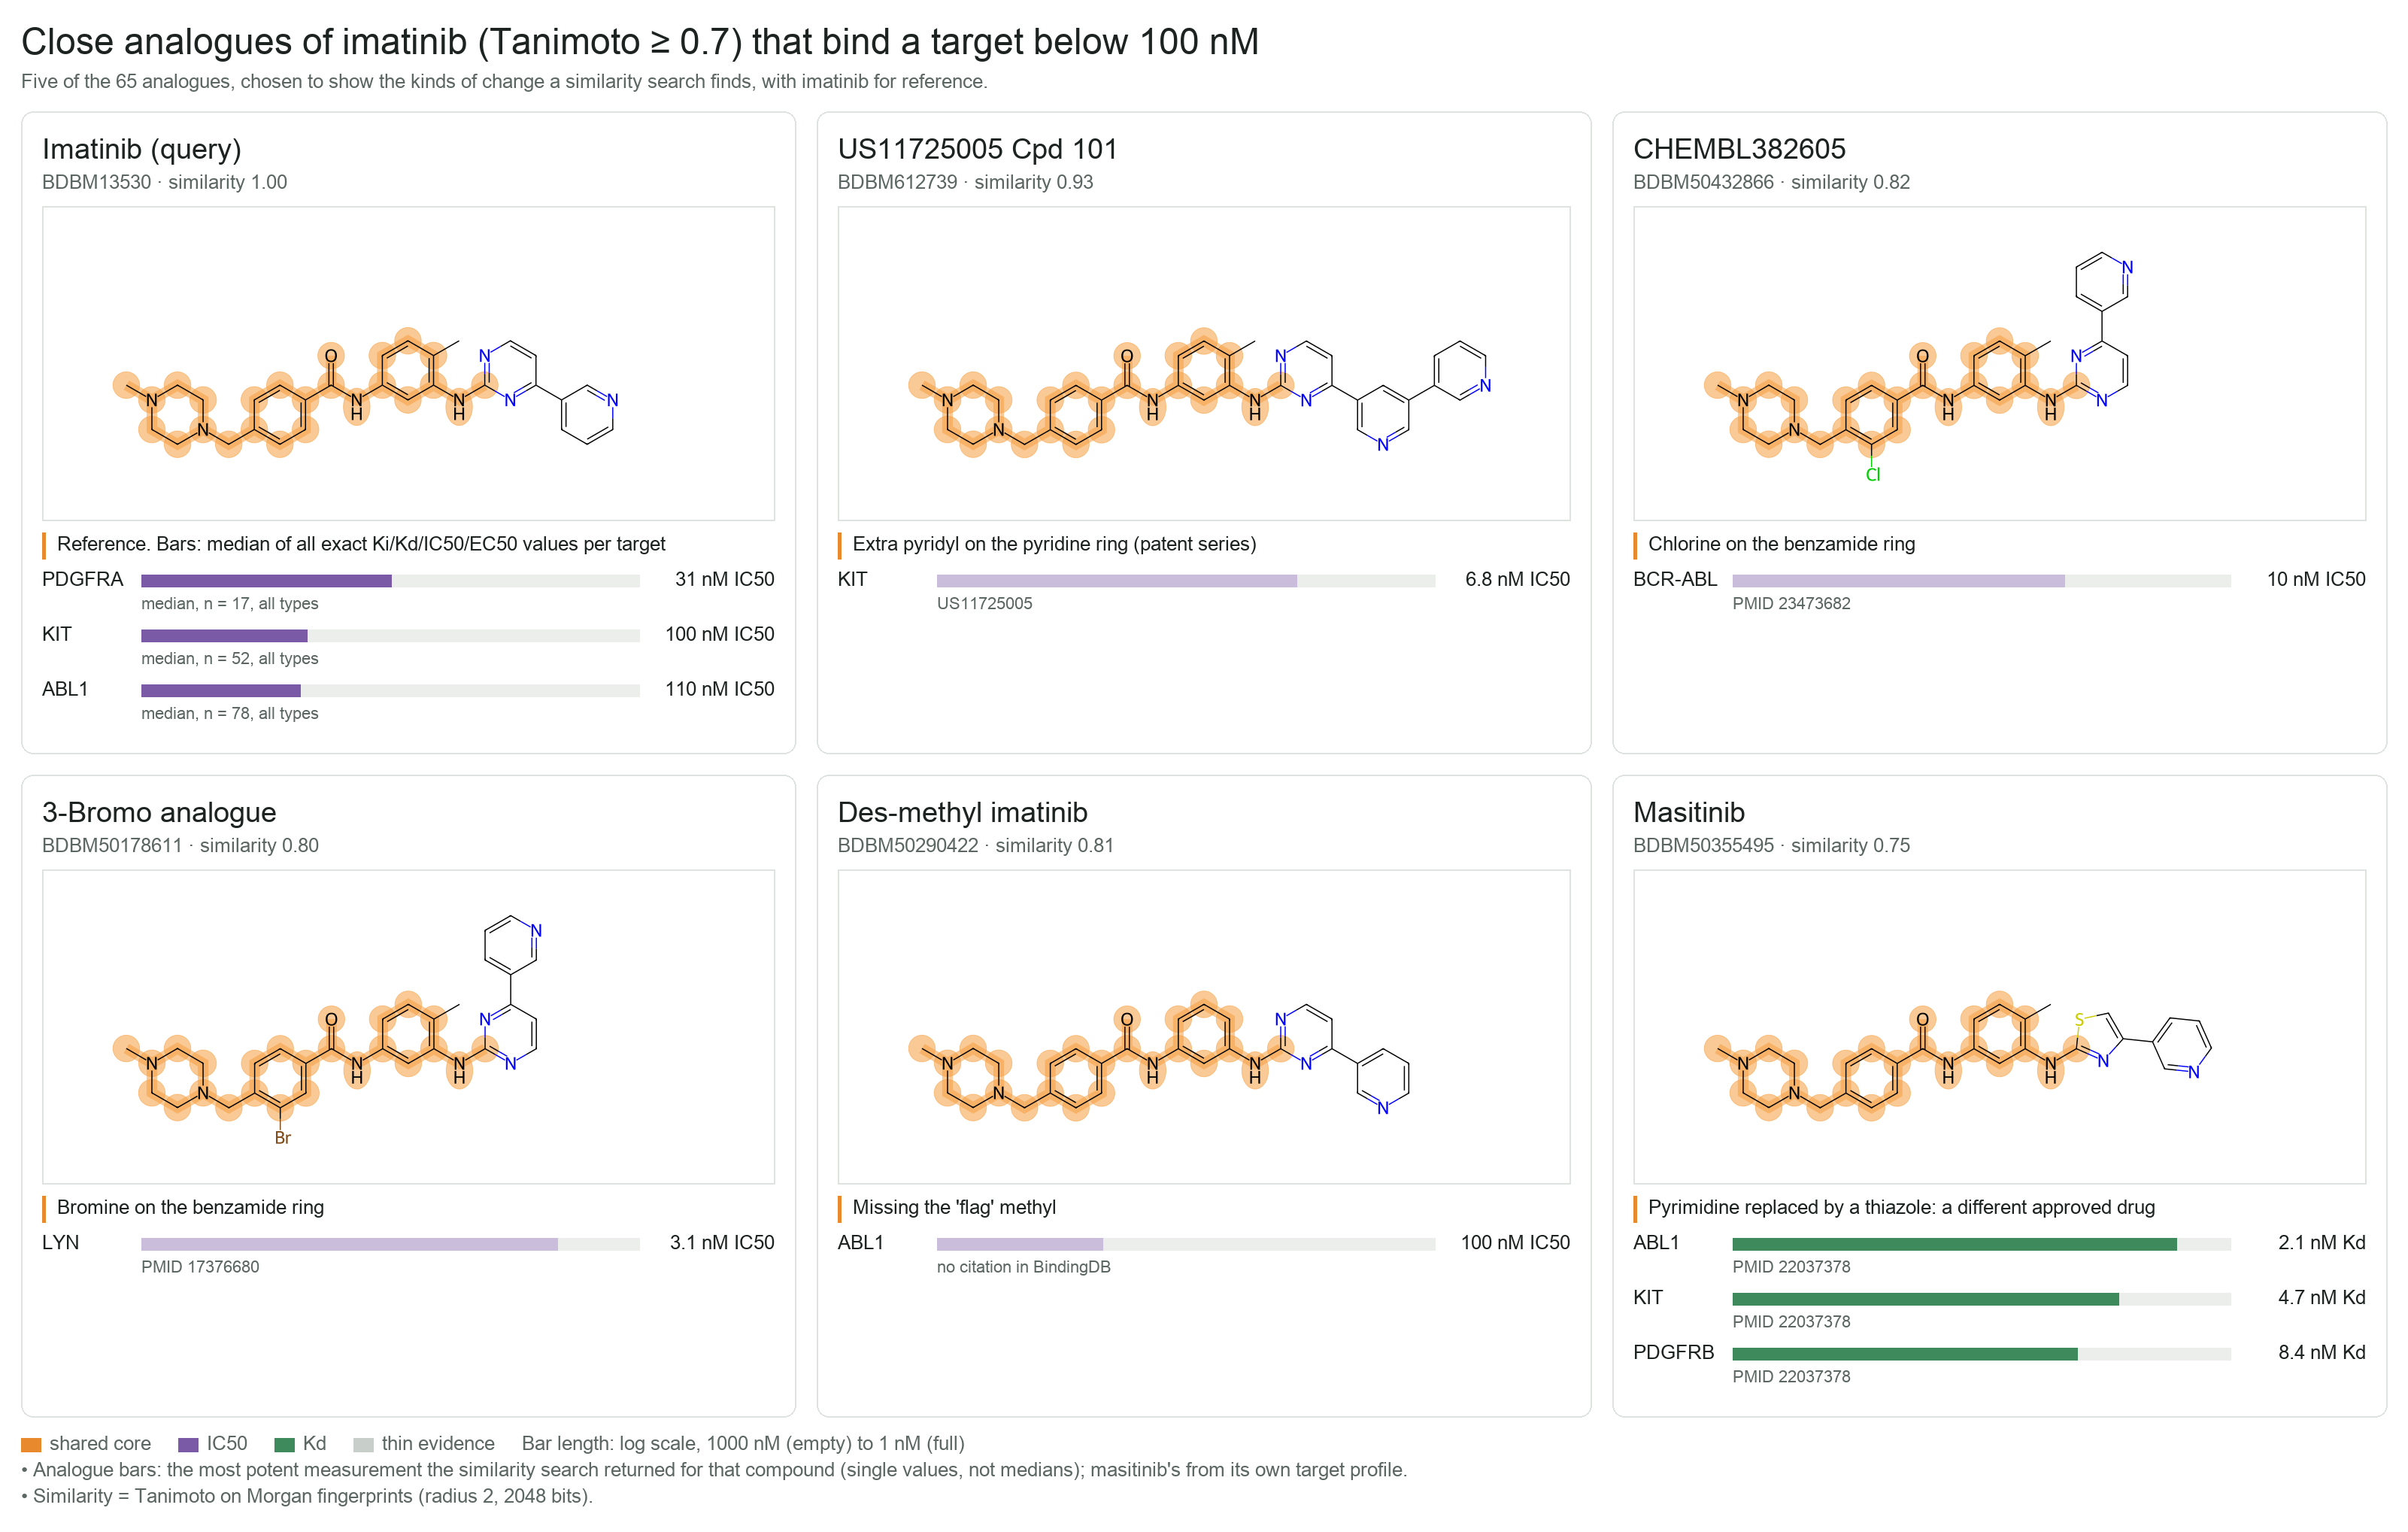

In [ ]:
# Figure 1 · draw_structure_grid draws it again
arguments = {
    'title': 'Close analogues of imatinib (Tanimoto ≥ 0.7) that bind a target below 100 nM',
    'compounds': [
        {
            'smiles': 'CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)CC1',
            'title': 'Imatinib (query)',
            'subtitle': 'BDBM13530 · similarity 1.00',
            'caption': 'Reference. Bars: median of all exact Ki/Kd/IC50/EC50 values per target',
            'bars': [
                {'label': 'PDGFRA', 'value_nm': 31.0, 'type': 'IC50', 'note': 'median, n = 17, all types'},
                {'label': 'KIT', 'value_nm': 100.0, 'type': 'IC50', 'note': 'median, n = 52, all types'},
                {'label': 'ABL1', 'value_nm': 110.0, 'type': 'IC50', 'note': 'median, n = 78, all types'},
            ],
        },
        {
            'smiles': 'CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3cccnc3)c2)CC1',
            'title': 'US11725005 Cpd 101',
            'subtitle': 'BDBM612739 · similarity 0.93',
            'caption': 'Extra pyridyl on the pyridine ring (patent series)',
            'bars': [{'label': 'KIT', 'value_nm': 6.8, 'type': 'IC50', 'note': 'US11725005', 'faint': True}],
        },
        {
            'smiles': 'CN1CCN(Cc2ccc(cc2Cl)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)CC1',
            'title': 'CHEMBL382605',
            'subtitle': 'BDBM50432866 · similarity 0.82',
            'caption': 'Chlorine on the benzamide ring',
            'bars': [
                {
                    'label': 'BCR-ABL',
                    'value_nm': 10.0,
                    'type': 'IC50',
                    'note': 'PMID 23473682',
                    'faint': True,
                },
            ],
        },
        {
            'smiles': 'CN1CCN(Cc2ccc(cc2Br)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)CC1',
            'title': '3-Bromo analogue',
            'subtitle': 'BDBM50178611 · similarity 0.80',
            'caption': 'Bromine on the benzamide ring',
            'bars': [
                {'label': 'LYN', 'value_nm': 3.1, 'type': 'IC50', 'note': 'PMID 17376680', 'faint': True},
            ],
        },
        {
            'smiles': 'CN1CCN(Cc2ccc(cc2)C(=O)Nc2cccc(Nc3nccc(n3)-c3cccnc3)c2)CC1',
            'title': 'Des-methyl imatinib',
            'subtitle': 'BDBM50290422 · similarity 0.81',
            'caption': "Missing the 'flag' methyl",
            'bars': [
                {
                    'label': 'ABL1',
                    'value_nm': 100.0,
                    'type': 'IC50',
                    'note': 'no citation in BindingDB',
                    'faint': True,
                },
            ],
        },
        {
            'smiles': 'Cc1ccc(cc1Nc2nc(cs2)c3cccnc3)NC(=O)c4ccc(cc4)CN5CCN(CC5)C',
            'title': 'Masitinib',
            'subtitle': 'BDBM50355495 · similarity 0.75',
            'caption': 'Pyrimidine replaced by a thiazole: a different approved drug',
            'bars': [
                {'label': 'ABL1', 'value_nm': 2.1, 'type': 'Kd', 'note': 'PMID 22037378'},
                {'label': 'KIT', 'value_nm': 4.7, 'type': 'Kd', 'note': 'PMID 22037378'},
                {'label': 'PDGFRB', 'value_nm': 8.4, 'type': 'Kd', 'note': 'PMID 22037378'},
            ],
        },
    ],
    'columns': 3,
    'description': 'Five of the 65 analogues, chosen to show the kinds of change a similarity search finds, with imatinib for reference.',
    'notes': [
        "Analogue bars: the most potent measurement the similarity search returned for that compound (single values, not medians); masitinib's from its own target profile.",
        'Similarity = Tanimoto on Morgan fingerprints (radius 2, 2048 bits).',
    ],
    'min_core_atoms': 8,
    'min_core_share': 0.8,
}
await replay.figure(1, 'draw_structure_grid', arguments)

**🧠 Assistant**

Out of 1,466,457 compounds, **83 have a Tanimoto similarity of 0.7 or more to imatinib**. **65 of them** have at least one Ki, Kd, IC50 or EC50 measurement at or below 100 nM.

The 83 include imatinib itself under three records (similarity 1.0) and two deuterated copies (N-CD3 on the piperazine, 0.90). The rest fall into three families:

- **Patent series around the pyridine ring.** Most of the potent hits (48 of the 65) come from two patents, US11725005 and US10906896 (24 each), which add a second (hetero)aryl ring to imatinib's pyridine. They are measured mainly on KIT, at 4–47 nM (median 9.7 nM).
- **Classic medicinal-chemistry analogues** from journal papers: halogens on the benzamide ring, a methyl on the pyridine, a missing methyl, or changes to the methylpiperazine.
- **Other drugs.** **Masitinib** (similarity 0.75) replaces imatinib's pyrimidine with a thiazole. It is a separate approved drug with 452 measurements (BDBM50355495), and it binds ABL1 at Kd 2.1 nM. Since the last release it also has a second record, BDBM734447, from a 2025 patent (US20250129067), with one PDGFR IC50 of 45 nM.

A selection of the most potent analogues, ranked by similarity:

| Compound | Similarity | Best measurement ≤ 100 nM | SMILES |
|---|---|---|---|
| US11725005 Cpd 101 (BDBM612739) | 0.93 | KIT IC50 6.8 nM | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3cccnc3)c2)CC1 |
| US11725005 Cpd 309 (BDBM612799) | 0.86 | KIT IC50 14 nM | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3ccccc3)c2)CC1 |
| 6-Methylpyridyl analogue (BDBM50313640) | 0.84 | KIT IC50 43 nM | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3ccc(C)nc3)c2)CC1 |
| CHEMBL382605 (BDBM50432866) | 0.82 | BCR-ABL IC50 10 nM | CN1CCN(Cc2ccc(cc2Cl)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)CC1 |
| US10906896 Cpd 830 (BDBM481130) | 0.82 | KIT Ki 6 nM | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3cc(C)ccn3)c2)CC1 |
| Des-methyl imatinib (BDBM50290422) | 0.81 | ABL1 IC50 100 nM | CN1CCN(Cc2ccc(cc2)C(=O)Nc2cccc(Nc3nccc(n3)-c3cccnc3)c2)CC1 |
| US10906896 Cpd 832 (BDBM481131) | 0.81 | KIT Ki 4 nM | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cncc(c3)-c3ccn(C)n3)c2)CC1 |
| 3-Bromo analogue (BDBM50178611) | 0.80 | LYN IC50 3.1 nM | CN1CCN(Cc2ccc(cc2Br)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)CC1 |
| Masitinib (BDBM50355495) | 0.75 | ABL1 Kd 2.1 nM | Cc1ccc(cc1Nc2nc(cs2)c3cccnc3)NC(=O)c4ccc(cc4)CN5CCN(CC5)C |

The figure below shows six of these, aligned and highlighted on the 25-atom core they all share: the methylpiperazinylmethyl-benzamide and the aniline up to the NH that links it to the (hetero)aryl ring. In imatinib's card, the bars are medians of all its exact Ki, Kd, IC50 and EC50 values per target (computed here with `run_sql`). In the other cards, each bar is the single best value the search returned.

One caution on the filtered list: imatinib's own "best measurement" there is an IC50 of 0.06 nM on HER2 (erbB-2, PMID 35696863). That is far outside anything else recorded for imatinib and is probably a unit or curation error; it is a reminder that "best value" picks up outliers.

**Lesson: what a similarity number means.** Similarity here is the Tanimoto coefficient on Morgan fingerprints (radius 2, 2048 bits): the share of small structural fragments two molecules have in common. Some rough guides:

- **1.0**: the same structure, ignoring stereo, salts and isotopes. That is why imatinib appears three times.
- **≥ 0.7**: close analogues, typically one or two changes to the same molecule.
- **0.4–0.6**: often the same chemical series, with larger changes.

A small change can still shift the score a lot. **Nilotinib**, a second-generation drug built on the same 2-anilino-4-(3-pyridyl)pyrimidine core, scores only **0.52** against imatinib, so this search misses it. To find every compound with a given core, use a substructure search (Example 2.5). Also note what the affinity filter does: "best measurement ≤ 100 nM" says only that the compound hit *something* that strongly, and each compound was measured on its own small panel of targets. The values are not comparable across compounds unless they come from the same assay.

### How this was answered

1. `chemical_name_to_smiles` for imatinib (BDBM13530, from its BindingDB synonym Gleevec).
2. `similarity_search` with imatinib's SMILES, `threshold=0.7`: 83 similar compounds across the whole database.
3. `similarity_search` with the same query and `max_value_nm=100`: 65 compounds, each with its most potent qualifying measurement. With an affinity filter, only the 747,819 compounds that have measurements are searched.
4. `chemical_name_to_smiles` for masitinib and nilotinib, and `find_targets_for_compound` for masitinib with `max_value_nm=100`: its 10 strongest targets, all Kd values from one kinase panel (PMID 22037378).
5. `run_sql` for imatinib's median values on PDGFRA, KIT and ABL1.
6. The nilotinib–imatinib similarity was computed with RDKit, using the same fingerprint settings (the same code gives 0.747 for masitinib, matching the search).
7. `draw_structure_grid`: draws the selected analogues aligned on their shared core.

### Try next

- "Which targets do imatinib's analogues hit most often?" Run the same search with `summarize_by_target` (see Example 2.5 for the substructure version).
- "Is (S)-crizotinib in BindingDB as its own compound, separate from crizotinib?" (Example 2.1)

## Verification

How each rerun call compared with its recorded result.

In [ ]:
replay.summary()

_Recorded: 7 tool calls, 1 figure to redraw. Run all cells to compare._

## How to cite

Cite this notebook (for example deposited with a DOI) together with the data and software it ran on:

- Data: BindingDB release 202611, https://www.bindingdb.org/rwd/bind/BDB-mySQL_All_202611_dmp.zip (SHA-256 daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381)
- Software: mcp-bindingdb v0.1.17, commit 79dae5d22c0f15b8ded9b49adc8b105f0463703a, https://github.com/sbl-sdsc/mcp-bindingdb
- Analysis: Example 2.2 — Similarity search: close analogues of imatinib, 2026-11-23, with claude-opus-5-5
- BindingDB: Liu T, Hwang L, Burley SK, Nitsche CI, Southan C, Walters WP, Gilson MK. BindingDB in 2024: a FAIR knowledgebase of protein-small molecule binding data. Nucleic Acids Research 53(D1):D1633-D1644, 2025. https://doi.org/10.1093/nar/gkae1075

As BibTeX, for this server, BindingDB and RDKit (used for structure search, properties and drawings):

```bibtex
@software{rose2026mcp-bindingdb,
  title={MCP BindingDB Server},
  author={Rose, P.W.},
  year={2026},
  url={https://github.com/sbl-sdsc/mcp-bindingdb}
}

@article{liu2025bindingdb,
  title={BindingDB in 2024: a FAIR knowledgebase of protein-small molecule binding data},
  author={Liu, T. and Hwang, L. and Burley, S.K. and Nitsche, C.I. and Southan, C. and Walters, W.P. and Gilson, M.K.},
  journal={Nucleic Acids Research},
  volume={53},
  number={D1},
  pages={D1633--D1644},
  year={2025},
  doi={10.1093/nar/gkae1075}
}

@software{rdkit,
  title={RDKit: Open-source cheminformatics},
  author={Landrum, G. and others},
  version={2026.03.6},
  url={https://www.rdkit.org},
  doi={10.5281/zenodo.591637}
}
```